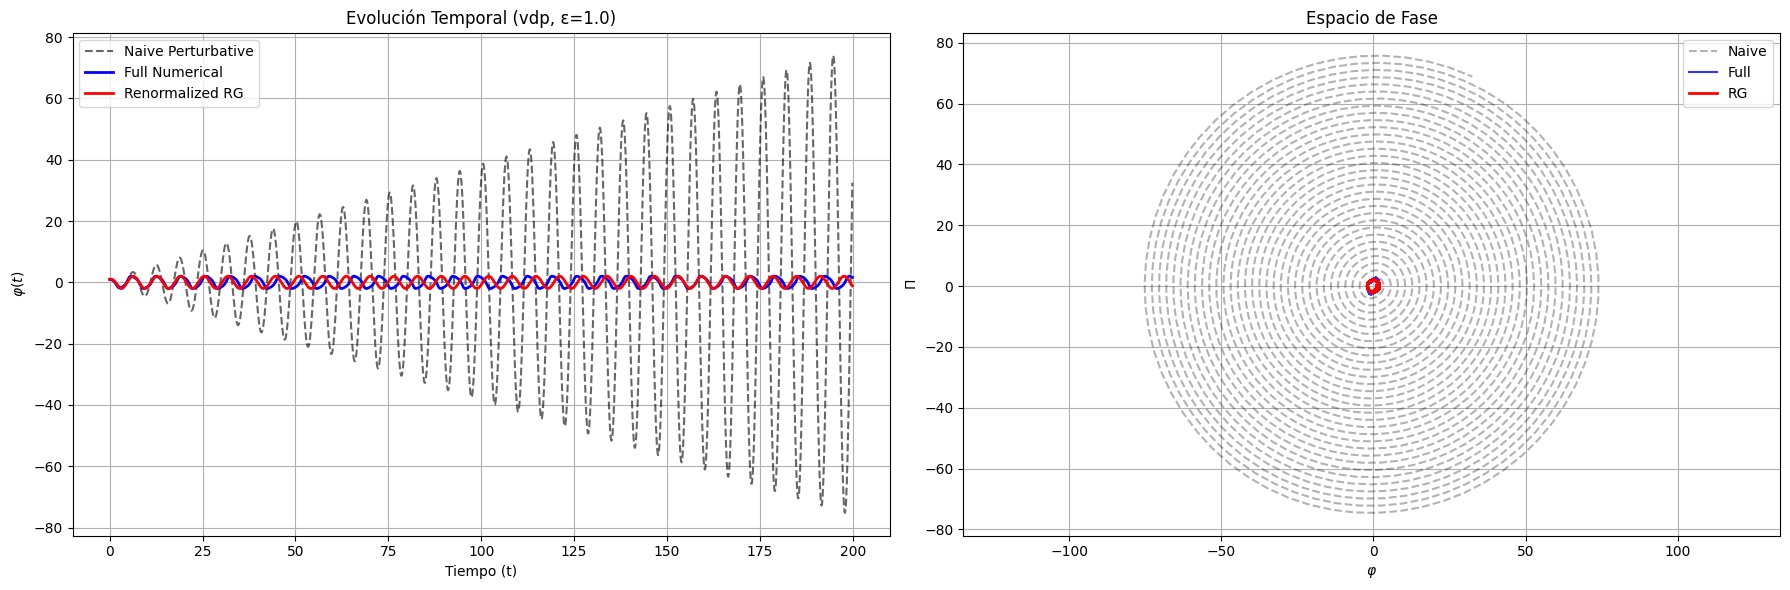

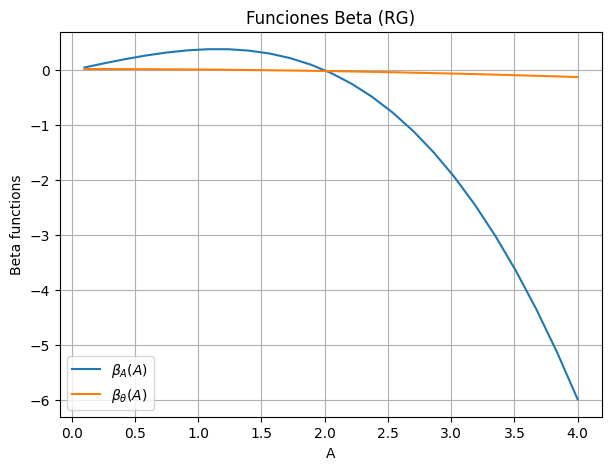

In [ ]:
# @title Algoritmo de Renormalización RG (Duffing / Van der Pol)

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d

# ---------------------------------------------------------
# 1. CONFIGURACIÓN Y PARÁMETROS
# ---------------------------------------------------------

system_type = "vdp"     # "duffing" o "vdp"

omega = 1.0
epsilon = 1.0
A0_init = 1.0

t_start = 0.0
t_end = 200.0
dt = 0.1
t_eval = np.arange(t_start, t_end, dt)

# ---------------------------------------------------------
# 2. DEFINICIÓN DE SISTEMAS
# ---------------------------------------------------------

def full_system(t, y):

    phi, Pi = y
    dphi = Pi

    if system_type == "duffing":
        dPi = -omega**2 * phi - epsilon * phi**3

    if system_type == "vdp":
        dPi = -omega**2 * phi + epsilon * (1 - phi**2) * Pi

    return [dphi, dPi]


# Background
def phi_0(t, A):
    return A*np.cos(omega*t)

def Pi_0(t, A):
    return -omega*A*np.sin(omega*t)


# Sistema perturbativo
def perturbative_system(t, y, A_fixed):

    phi1, Pi1 = y

    p0 = phi_0(t,A_fixed)
    pi0 = Pi_0(t,A_fixed)

    dphi1 = Pi1

    if system_type == "duffing":
        source = -p0**3

    if system_type == "vdp":
        source = pi0*(1-p0**2)

    dPi1 = -omega**2*phi1 + source

    return [dphi1,dPi1]


# ---------------------------------------------------------
# 3. NÚCLEO DE RENORMALIZACIÓN
# ---------------------------------------------------------

A_grid = np.linspace(0.1,4.0,25)

beta_A_vals = []
beta_theta_vals = []

for A_val in A_grid:

    T_period = 2*np.pi/omega
    t_short = np.linspace(0,6*T_period,2000)

    sol_pert = solve_ivp(
        perturbative_system,
        [0,6*T_period],
        [0,0],
        args=(A_val,),
        t_eval=t_short
    )

    phi1 = sol_pert.y[0]

    # DIRECCIONES TANGENTES CORRECTAS

    X1 = t_short*np.cos(omega*t_short)            # ∂φ/∂A
    X2 = -A_val*t_short*np.sin(omega*t_short)     # ∂φ/∂θ

    X = np.vstack([X1,X2]).T

    beta = np.linalg.lstsq(X,phi1,rcond=None)[0]

    beta_A_vals.append(beta[0])
    beta_theta_vals.append(beta[1])


beta_A_function = interp1d(A_grid,beta_A_vals,
                           kind='cubic',fill_value="extrapolate")

beta_theta_function = interp1d(A_grid,beta_theta_vals,
                               kind='cubic',fill_value="extrapolate")


# ---------------------------------------------------------
# 4. RESOLVIENDO LOS TRES MÉTODOS
# ---------------------------------------------------------

# --- FULL ---
sol_full = solve_ivp(
    full_system,
    [t_start,t_end],
    [A0_init,0],
    t_eval=t_eval
)

y_full = sol_full.y[0]
pi_full = sol_full.y[1]


# --- NAIVE ---
sol_naive = solve_ivp(
    perturbative_system,
    [t_start,t_end],
    [0,0],
    args=(A0_init,),
    t_eval=t_eval
)

y_naive = phi_0(t_eval,A0_init) + epsilon*sol_naive.y[0]
pi_naive = Pi_0(t_eval,A0_init) + epsilon*sol_naive.y[1]


# --- RG ---
def RG_flow(t,y):

    A,theta = y

    dA = epsilon*beta_A_function(A)
    dtheta = epsilon*beta_theta_function(A)

    return [dA,dtheta]


sol_RG = solve_ivp(
    RG_flow,
    [t_start,t_end],
    [A0_init,0],
    t_eval=t_eval
)

A_t = sol_RG.y[0]
theta_t = sol_RG.y[1]


# reconstrucción

y_RG = A_t*np.cos(omega*t_eval + theta_t)

dA_dt = epsilon*beta_A_function(A_t)
dtheta_dt = epsilon*beta_theta_function(A_t)

pi_RG = (
    dA_dt*np.cos(omega*t_eval + theta_t)
    - A_t*(omega + dtheta_dt)*np.sin(omega*t_eval + theta_t)
)


# ---------------------------------------------------------
# 5. GRÁFICOS
# ---------------------------------------------------------

fig,(ax1,ax2)=plt.subplots(1,2,figsize=(18,6))

ax1.set_title(f"Evolución Temporal ({system_type}, ε={epsilon})")

ax1.plot(t_eval,y_naive,'k--',alpha=0.6,
         label='Naive Perturbative')

ax1.plot(t_eval,y_full,'b-',linewidth=2,
         label='Full Numerical')

ax1.plot(t_eval,y_RG,'r-',linewidth=2,
         label='Renormalized RG')

ax1.set_xlabel('Tiempo (t)')
ax1.set_ylabel(r'$\varphi(t)$')
ax1.legend()
ax1.grid(True)


ax2.set_title("Espacio de Fase")

ax2.plot(y_naive,pi_naive,'k--',alpha=0.3,label='Naive')

ax2.plot(y_full,pi_full,'b-',alpha=0.8,label='Full')

ax2.plot(y_RG,pi_RG,'r-',linewidth=2,label='RG')

ax2.set_xlabel(r'$\varphi$')
ax2.set_ylabel(r'$\Pi$')
ax2.axis('equal')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 6. FUNCIONES BETA
# ---------------------------------------------------------

plt.figure(figsize=(7,5))

plt.plot(A_grid,beta_A_vals,label=r'$\beta_A(A)$')
plt.plot(A_grid,beta_theta_vals,label=r'$\beta_\theta(A)$')

plt.xlabel("A")
plt.ylabel("Beta functions")
plt.title("Funciones Beta (RG)")
plt.grid(True)
plt.legend()

plt.show()


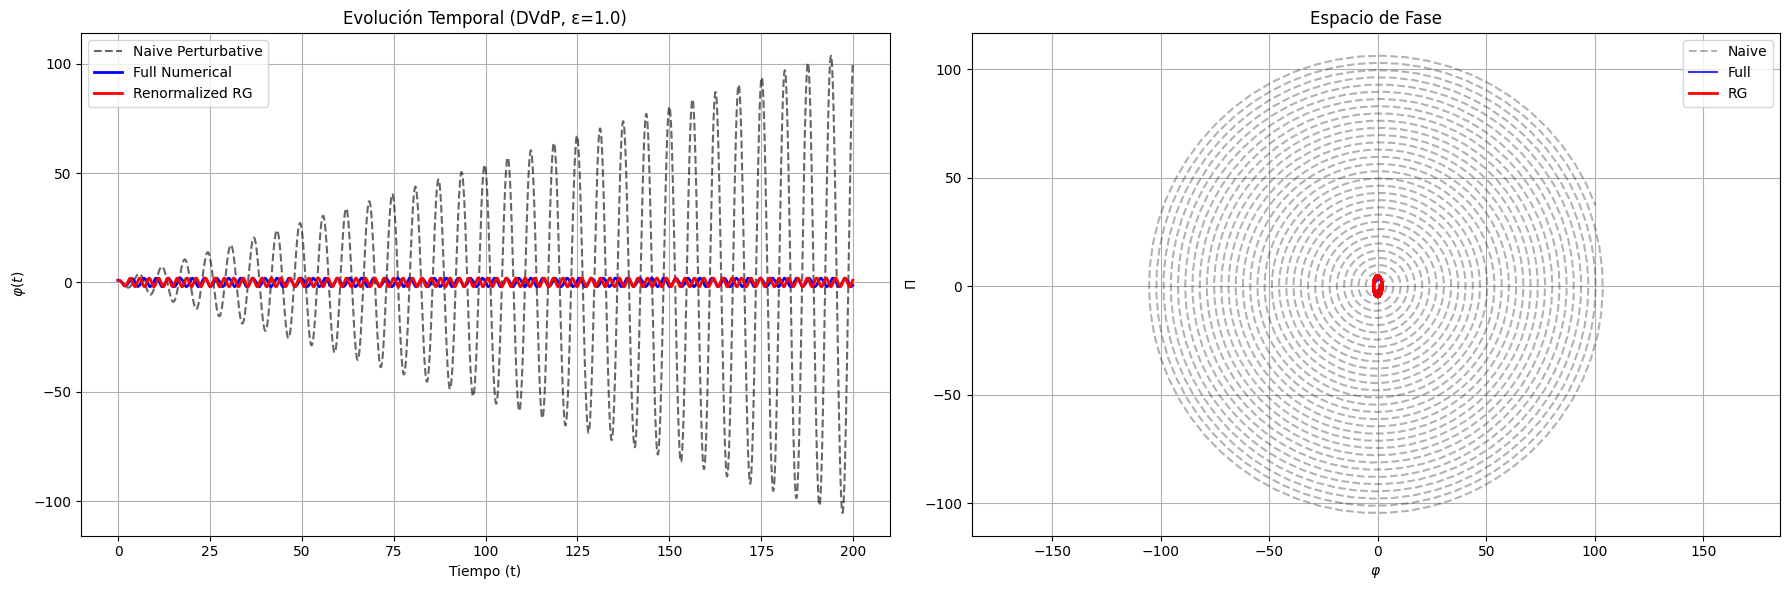

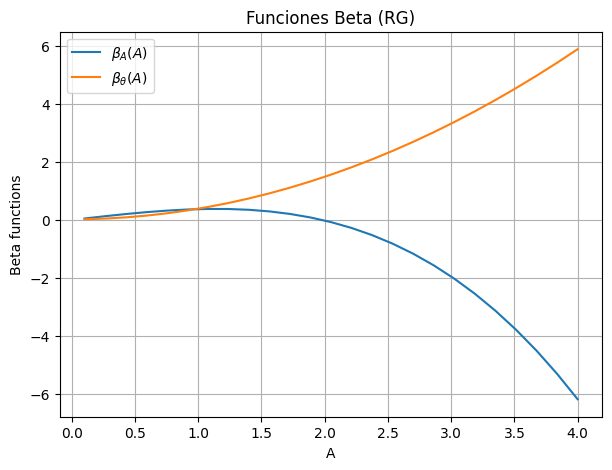

In [ ]:
# @title Algoritmo de Renormalización RG DVdP

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d

# ---------------------------------------------------------
# 1. CONFIGURACIÓN Y PARÁMETROS
# ---------------------------------------------------------

omega = 1.0
epsilon = 1.0
A0_init = 1.0

t_start = 0.0
t_end = 200.0
dt = 0.1
t_eval = np.arange(t_start, t_end, dt)

# ---------------------------------------------------------
# 2. DEFINICIÓN DE SISTEMAS
# ---------------------------------------------------------

def full_system(t, y):

    phi, Pi = y
    dphi = Pi
    dPi = -omega**2 * phi - epsilon * phi**3 + epsilon * (1 - phi**2) * Pi

    return [dphi, dPi]

# Background
def phi_0(t, A):
    return A*np.cos(omega*t)

def Pi_0(t, A):
    return -omega*A*np.sin(omega*t)


# Sistema perturbativo
def perturbative_system(t, y, A_fixed):

    phi1, Pi1 = y

    p0 = phi_0(t,A_fixed)
    pi0 = Pi_0(t,A_fixed)

    dphi1 = Pi1

    source = -p0**3 + pi0*(1-p0**2)

    dPi1 = -omega**2*phi1 + source

    return [dphi1,dPi1]


# ---------------------------------------------------------
# 3. NÚCLEO DE RENORMALIZACIÓN
# ---------------------------------------------------------

A_grid = np.linspace(0.1,4.0,25)

beta_A_vals = []
beta_theta_vals = []

for A_val in A_grid:

    T_period = 2*np.pi/omega
    t_short = np.linspace(0,6*T_period,2000)

    sol_pert = solve_ivp(
        perturbative_system,
        [0,6*T_period],
        [0,0],
        args=(A_val,),
        t_eval=t_short
    )

    phi1 = sol_pert.y[0]

    # DIRECCIONES TANGENTES CORRECTAS

    X1 = t_short*np.cos(omega*t_short)            # ∂φ/∂A
    X2 = -A_val*t_short*np.sin(omega*t_short)     # ∂φ/∂θ

    X = np.vstack([X1,X2]).T

    beta = np.linalg.lstsq(X,phi1,rcond=None)[0]

    beta_A_vals.append(beta[0])
    beta_theta_vals.append(beta[1])


beta_A_function = interp1d(A_grid,beta_A_vals,
                           kind='cubic',fill_value="extrapolate")

beta_theta_function = interp1d(A_grid,beta_theta_vals,
                               kind='cubic',fill_value="extrapolate")


# ---------------------------------------------------------
# 4. RESOLVIENDO LOS TRES MÉTODOS
# ---------------------------------------------------------

# --- FULL ---
sol_full = solve_ivp(
    full_system,
    [t_start,t_end],
    [A0_init,0],
    t_eval=t_eval
)

y_full = sol_full.y[0]
pi_full = sol_full.y[1]


# --- NAIVE ---
sol_naive = solve_ivp(
    perturbative_system,
    [t_start,t_end],
    [0,0],
    args=(A0_init,),
    t_eval=t_eval
)

y_naive = phi_0(t_eval,A0_init) + epsilon*sol_naive.y[0]
pi_naive = Pi_0(t_eval,A0_init) + epsilon*sol_naive.y[1]


# --- RG ---
def RG_flow(t,y):

    A,theta = y

    dA = epsilon*beta_A_function(A)
    dtheta = epsilon*beta_theta_function(A)

    return [dA,dtheta]


sol_RG = solve_ivp(
    RG_flow,
    [t_start,t_end],
    [A0_init,0],
    t_eval=t_eval
)

A_t = sol_RG.y[0]
theta_t = sol_RG.y[1]


# reconstrucción

y_RG = A_t*np.cos(omega*t_eval + theta_t)

dA_dt = epsilon*beta_A_function(A_t)
dtheta_dt = epsilon*beta_theta_function(A_t)

pi_RG = (
    dA_dt*np.cos(omega*t_eval + theta_t)
    - A_t*(omega + dtheta_dt)*np.sin(omega*t_eval + theta_t)
)


# ---------------------------------------------------------
# 5. GRÁFICOS
# ---------------------------------------------------------

fig,(ax1,ax2)=plt.subplots(1,2,figsize=(18,6))

ax1.set_title(f"Evolución Temporal (DVdP, ε={epsilon})")

ax1.plot(t_eval,y_naive,'k--',alpha=0.6,
         label='Naive Perturbative')

ax1.plot(t_eval,y_full,'b-',linewidth=2,
         label='Full Numerical')

ax1.plot(t_eval,y_RG,'r-',linewidth=2,
         label='Renormalized RG')

ax1.set_xlabel('Tiempo (t)')
ax1.set_ylabel(r'$\varphi(t)$')
ax1.legend()
ax1.grid(True)


ax2.set_title("Espacio de Fase")

ax2.plot(y_naive,pi_naive,'k--',alpha=0.3,label='Naive')

ax2.plot(y_full,pi_full,'b-',alpha=0.8,label='Full')

ax2.plot(y_RG,pi_RG,'r-',linewidth=2,label='RG')

ax2.set_xlabel(r'$\varphi$')
ax2.set_ylabel(r'$\Pi$')
ax2.axis('equal')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 6. FUNCIONES BETA
# ---------------------------------------------------------

plt.figure(figsize=(7,5))

plt.plot(A_grid,beta_A_vals,label=r'$\beta_A(A)$')
plt.plot(A_grid,beta_theta_vals,label=r'$\beta_\theta(A)$')

plt.xlabel("A")
plt.ylabel("Beta functions")
plt.title("Funciones Beta (RG)")
plt.grid(True)
plt.legend()

plt.show()
